# Experiment 12: Iris Flower Classification using KNN
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement **Iris Flower Classification** using the **K-Nearest Neighbours** algorithm.

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


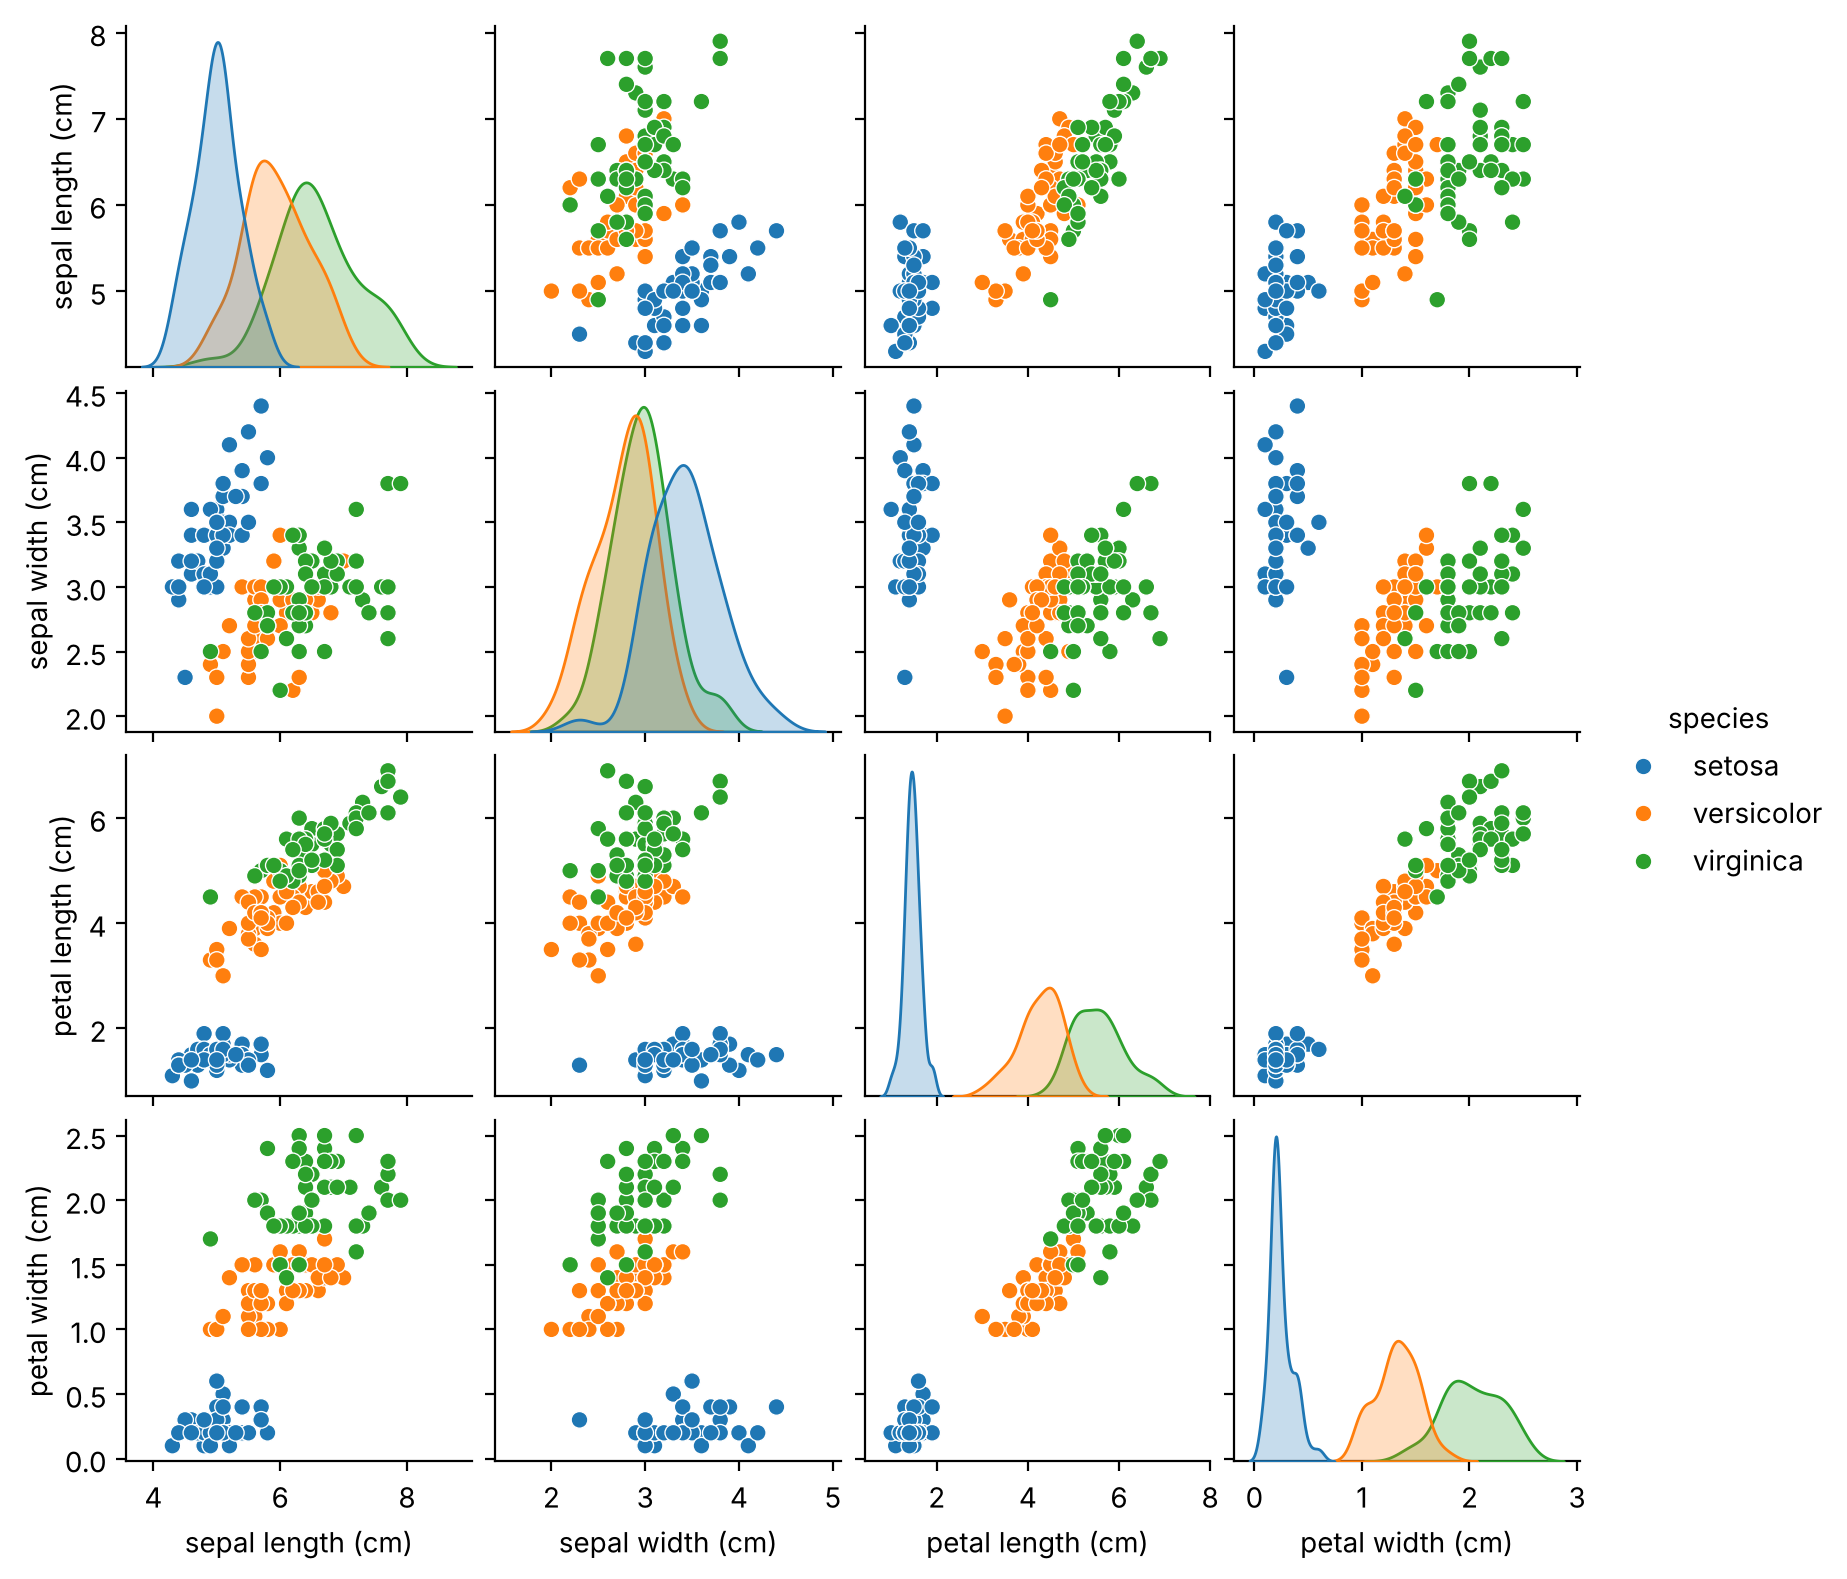

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
print(df['species'].value_counts())
sns.pairplot(df.drop(columns='target'), hue='species', height=2)
plt.show()

Best k from cross-validation: 5 | CV accuracy: 0.9667


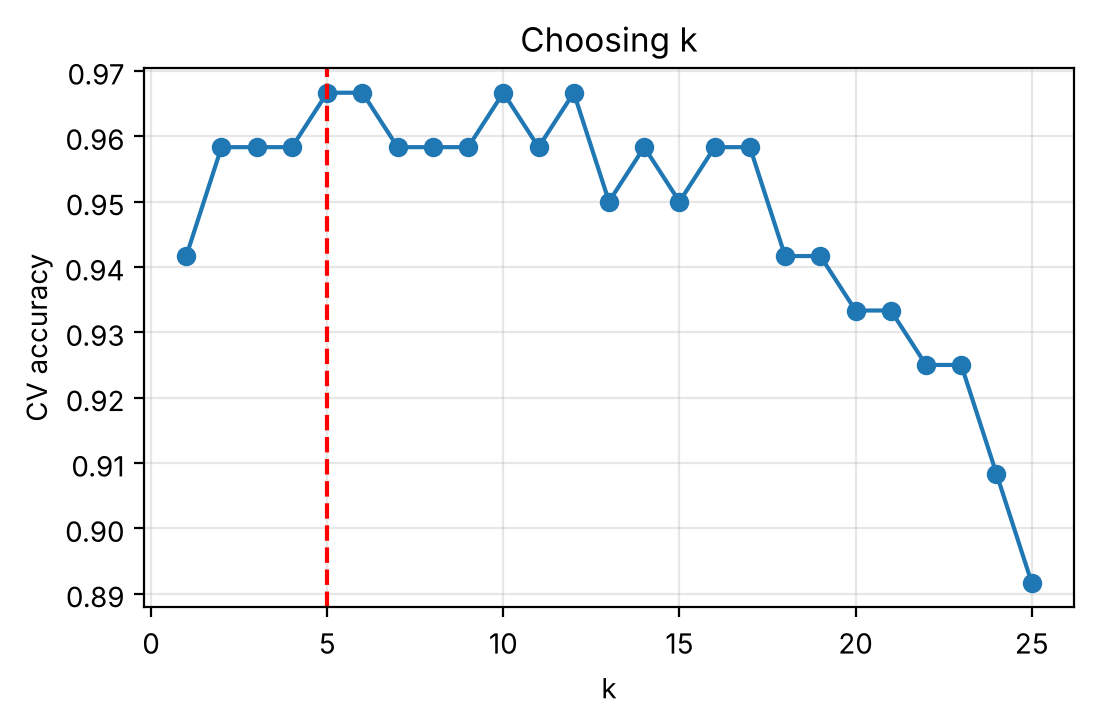

In [2]:
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)

# choose k with 5-fold cross-validation
ks = range(1, 26)
cv = [cross_val_score(KNeighborsClassifier(k), Xtr, y_train, cv=5).mean() for k in ks]
best_k = list(ks)[int(np.argmax(cv))]
print('Best k from cross-validation:', best_k, '| CV accuracy:', round(max(cv), 4))

plt.figure(figsize=(6, 3.5))
plt.plot(list(ks), cv, marker='o'); plt.axvline(best_k, color='r', ls='--')
plt.xlabel('k'); plt.ylabel('CV accuracy'); plt.title('Choosing k'); plt.grid(alpha=0.3); plt.show()

Test accuracy: 0.9333 

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



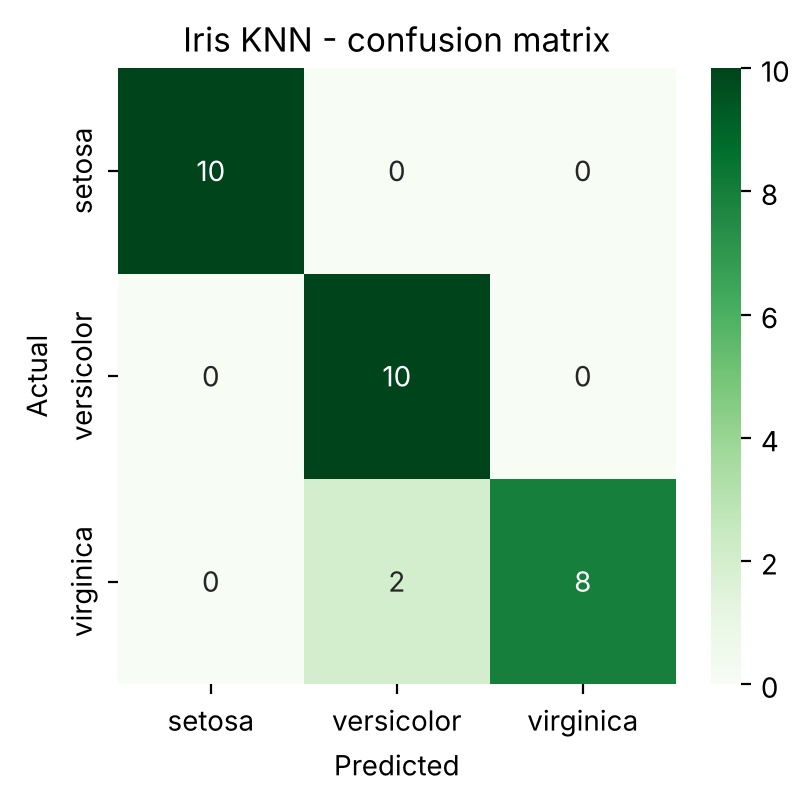

[5.1 3.5 1.4 0.2] -> setosa
[6.  2.9 4.5 1.5] -> versicolor
[6.9 3.1 5.4 2.1] -> virginica


In [3]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr, y_train)
pred = knn.predict(Xte)
print('Test accuracy:', round(accuracy_score(y_test, pred), 4), '\n')
print(classification_report(y_test, pred, target_names=iris.target_names))

plt.figure(figsize=(4.5, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Greens',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Iris KNN - confusion matrix'); plt.show()

# classify new flowers: [sepal length, sepal width, petal length, petal width]
new = pd.DataFrame([[5.1, 3.5, 1.4, 0.2], [6.0, 2.9, 4.5, 1.5], [6.9, 3.1, 5.4, 2.1]],
                   columns=iris.feature_names)
for row, p in zip(new.values, knn.predict(scaler.transform(new))):
    print(row, '->', iris.target_names[p])

## Result
K-NN classifies Iris flowers with about 90-100 % test accuracy. `setosa` is perfectly separable, while a few `versicolor` / `virginica` samples can overlap.